# L1: Correlation, Autocorrelation & Partial Autocorrelation

In [1]:
# If statsmodels is missing, uncomment:
%pip install statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (10, 3.5)
plt.rcParams["axes.grid"] = True



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Put the CSVs in the same folder as your notebook
PATH_CPI   = "data/CPIAUCSL.csv"
PATH_UNEMP = "data/UNRATE.csv"

# CPI: columns are 'observation_date' and 'CPIAUCSL'
cpi = (pd.read_csv(PATH_CPI, parse_dates=["observation_date"])
        .rename(columns={"observation_date": "date", "CPIAUCSL": "cpi"})
        .set_index("date")
        .sort_index())

# UNRATE: columns are 'observation_date' and 'UNRATE'
unrate = (pd.read_csv(PATH_UNEMP, parse_dates=["observation_date"])
            .rename(columns={"observation_date": "date", "UNRATE": "unrate"})
            .set_index("date")
            .sort_index())

# Merge and align to Month Start (MS) — consistent, explicit calendar
df = (cpi.join(unrate, how="inner")
        .asfreq("MS"))

print(df.head(3))
print("\nRange:", df.index.min().date(), "→", df.index.max().date())
print("Inferred frequency:", pd.infer_freq(df.index))


              cpi  unrate
date                     
1948-01-01  23.68     3.4
1948-02-01  23.67     3.8
1948-03-01  23.50     4.0

Range: 1948-01-01 → 2025-07-01
Inferred frequency: MS


In [3]:
df["inflation_mom"] = np.log(df["cpi"]).diff() * 100   # monthly % inflation
df["unrate_diff"]   = df["unrate"].diff()               # change in unemployment, pp

df_tr = df[["inflation_mom", "unrate_diff"]].dropna()
df_tr.head(3)


,inflation_mom,unrate_diff
date,,
1948-02-01,-0.042239,0.4
1948-03-01,-0.720800,0.2
1948-04-01,1.352514,-0.1


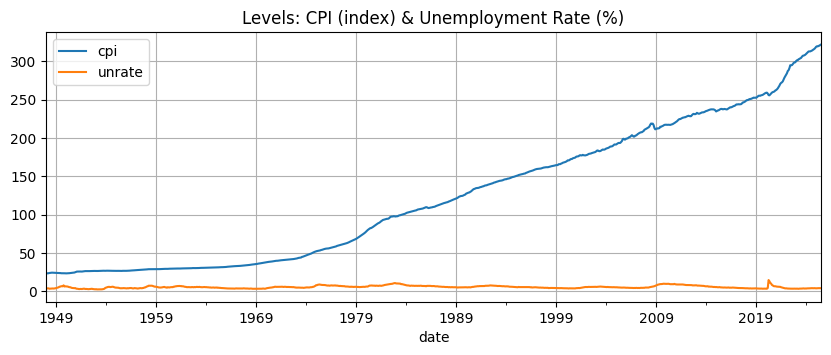

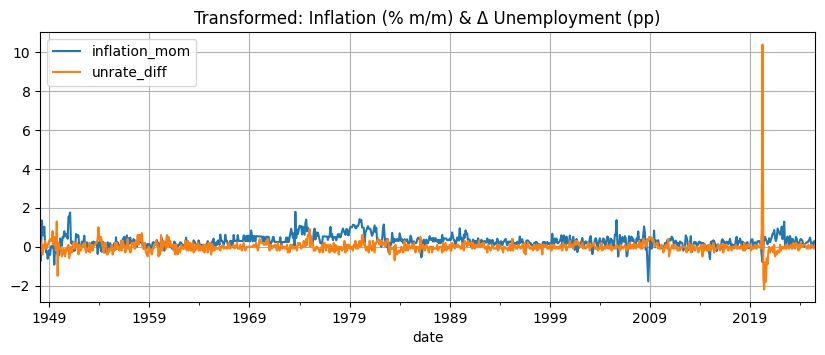

In [4]:
ax = df[["cpi","unrate"]].plot(title="Levels: CPI (index) & Unemployment Rate (%)")
# plt.savefig("levels_cpi_unrate.png", dpi=200, bbox_inches="tight")
plt.show()

ax = df_tr.plot(title="Transformed: Inflation (% m/m) & Δ Unemployment (pp)")
# plt.savefig("transforms_infl_unrate_diff.png", dpi=200, bbox_inches="tight")
plt.show()


In [5]:
corr_now = df_tr.corr()
print(corr_now.round(3))


               inflation_mom  unrate_diff
inflation_mom          1.000       -0.115
unrate_diff           -0.115        1.000


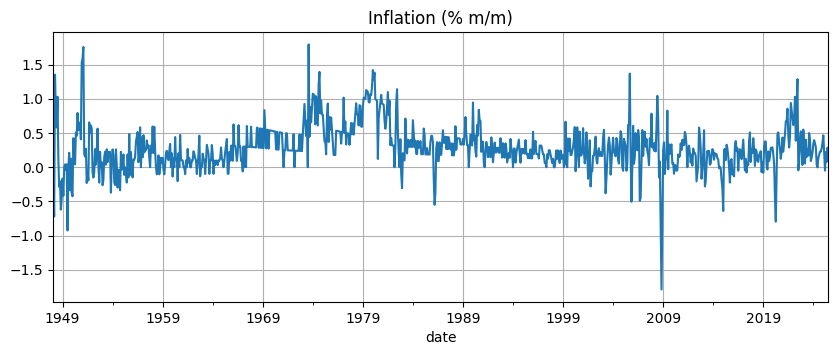

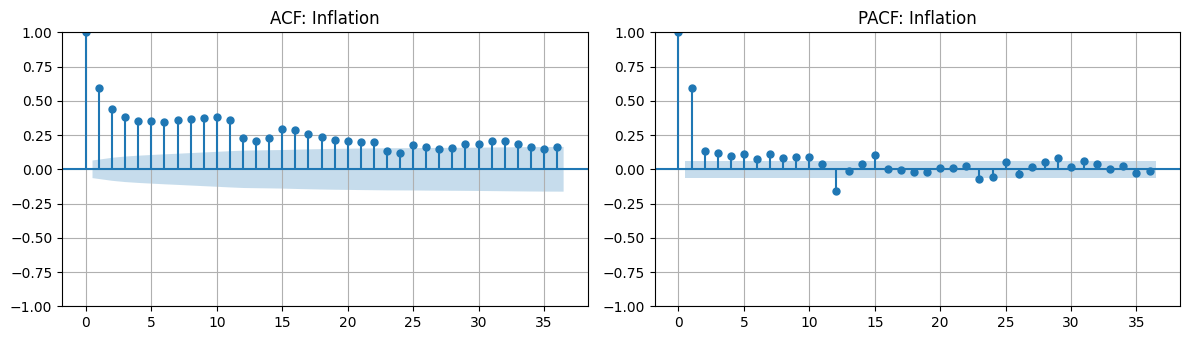

In [6]:
# Inflation ACF/PACF
series = df_tr["inflation_mom"]

fig, ax = plt.subplots()
series.plot(ax=ax, title="Inflation (% m/m)")
# plt.savefig("series_inflation_mom.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1,2, figsize=(12,3.5))
plot_acf(series, lags=36, ax=axes[0]); axes[0].set_title("ACF: Inflation")
plot_pacf(series, lags=36, method="ywm", ax=axes[1]); axes[1].set_title("PACF: Inflation")
plt.tight_layout()
# plt.savefig("acf_pacf_inflation.png", dpi=200, bbox_inches="tight")
plt.show()


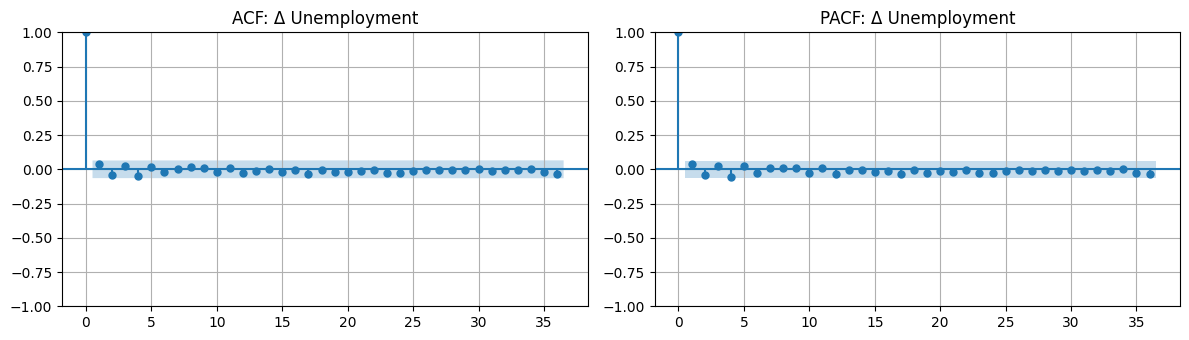

In [7]:
series = df_tr["unrate_diff"]

fig, axes = plt.subplots(1,2, figsize=(12,3.5))
plot_acf(series, lags=36, ax=axes[0]); axes[0].set_title("ACF: Δ Unemployment")
plot_pacf(series, lags=36, method="ywm", ax=axes[1]); axes[1].set_title("PACF: Δ Unemployment")
plt.tight_layout()
# plt.savefig("acf_pacf_unrate_diff.png", dpi=200, bbox_inches="tight")
plt.show()


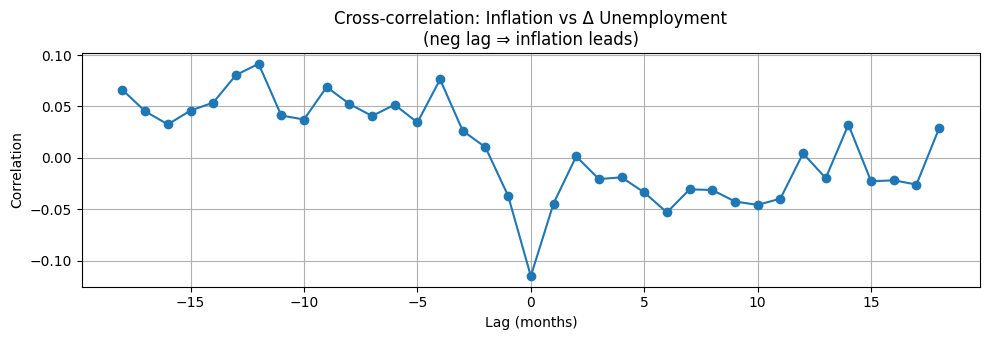

-18    0.066
-17    0.045
-16    0.033
-15    0.046
-14    0.054
-13    0.081
-12    0.092
-11    0.041
-10    0.037
-9     0.069
-8     0.053
-7     0.041
-6     0.052
-5     0.034
-4     0.076
-3     0.026
-2     0.010
-1    -0.037
 0    -0.115
 1    -0.045
 2     0.001
 3    -0.021
 4    -0.019
 5    -0.034
 6    -0.053
 7    -0.031
 8    -0.031
 9    -0.043
 10   -0.046
 11   -0.040
 12    0.004
 13   -0.020
 14    0.032
 15   -0.023
 16   -0.022
 17   -0.026
 18    0.029
dtype: float64

In [8]:
a = df_tr["inflation_mom"].copy()
b = df_tr["unrate_diff"].copy()

def xcorr(a, b, max_lag=18):
    """Cross-correlation by shifting.
    Negative lag => a leads b; Positive lag => b leads a."""
    out = {}
    for L in range(-max_lag, max_lag+1):
        if L < 0:
            out[L] = a.shift(-L).corr(b)  # a leads b
        else:
            out[L] = a.corr(b.shift(L))   # b leads a
    return pd.Series(out)

xc = xcorr(a, b, max_lag=18)
ax = xc.plot(marker="o", title="Cross-correlation: Inflation vs Δ Unemployment\n(neg lag ⇒ inflation leads)")
ax.set_xlabel("Lag (months)")
ax.set_ylabel("Correlation")
plt.tight_layout()
# plt.savefig("crosscorr_infl_vs_unrate_diff.png", dpi=200, bbox_inches="tight")
plt.show()

xc.round(3)


# L2: Autoregressive (AR) Models 

In [11]:
# !pip install statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (10, 3.5)
plt.rcParams["axes.grid"] = True

# --- Load CPI & UNRATE (same as Lesson 1) ---
PATH_CPI   = "data/CPIAUCSL.csv"
PATH_UNEMP = "data/UNRATE.csv"

cpi = (pd.read_csv(PATH_CPI, parse_dates=["observation_date"])
         .rename(columns={"observation_date":"date","CPIAUCSL":"cpi"})
         .set_index("date").sort_index())

unrate = (pd.read_csv(PATH_UNEMP, parse_dates=["observation_date"])
            .rename(columns={"observation_date":"date","UNRATE":"unrate"})
            .set_index("date").sort_index())

df = (cpi.join(unrate, how="inner").asfreq("MS"))
df["inflation_mom"] = np.log(df["cpi"]).diff()*100
df["unrate_diff"]   = df["unrate"].diff()
df_tr = df[["inflation_mom", "unrate_diff"]].dropna()


In [12]:
y = df_tr["inflation_mom"].copy()

# Augmented Dickey–Fuller test (H0: unit root / non-stationary)
adf_stat, pval, *_ = adfuller(y.dropna(), autolag="AIC")
print(f"ADF stat: {adf_stat:.3f}  |  p-value: {pval:.4f}")


ADF stat: -4.081  |  p-value: 0.0010


In [13]:
results = []
for p in range(0, 7):
    model = ARIMA(y, order=(p,0,0))
    fit   = model.fit()
    results.append({"p": p, "AIC": fit.aic, "BIC": fit.bic})

order_tbl = pd.DataFrame(results).set_index("p").sort_values("AIC")
print(order_tbl)
best_p = int(order_tbl.index[0])
print(f"\nBest by AIC appears to be p={best_p}")


          AIC         BIC
p                        
6  125.038835  163.720312
5  127.813699  161.659991
4  137.530287  166.541395
3  143.730374  167.906297
2  154.296971  173.637710
1  170.240760  184.746314
0  575.537670  585.208039

Best by AIC appears to be p=6


In [14]:
ar1 = ARIMA(y, order=(1,0,0)).fit()
print(ar1.summary())

ar2 = ARIMA(y, order=(2,0,0)).fit()
print(ar2.summary())


                               SARIMAX Results                                
Dep. Variable:          inflation_mom   No. Observations:                  930
Model:                 ARIMA(1, 0, 0)   Log Likelihood                 -82.120
Date:                Mon, 02 Feb 2026   AIC                            170.241
Time:                        13:21:06   BIC                            184.746
Sample:                    02-01-1948   HQIC                           175.773
                         - 07-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2800      0.022     13.009      0.000       0.238       0.322
ar.L1          0.5955      0.016     37.176      0.000       0.564       0.627
sigma2         0.0698      0.002     40.023      0.0

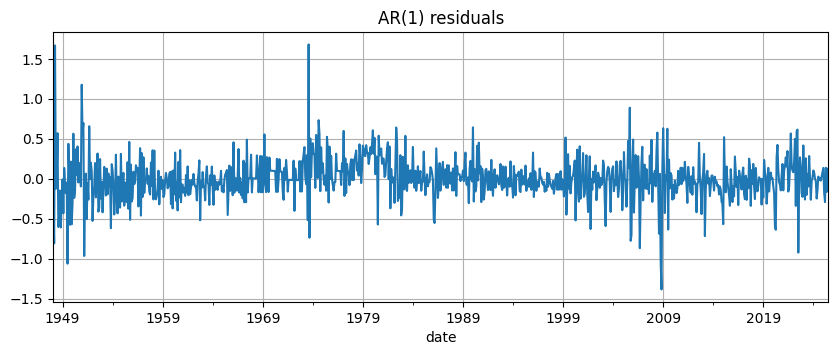

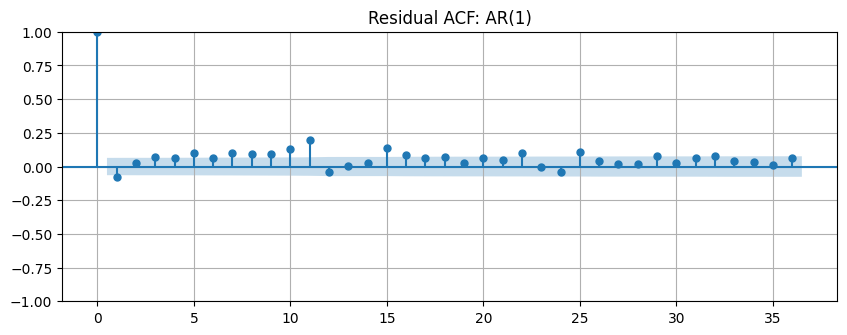

      lb_stat     lb_pvalue
12  105.84036  3.964441e-17


In [15]:
resid = ar1.resid.dropna()

fig, ax = plt.subplots()
resid.plot(ax=ax, title="AR(1) residuals")
# plt.savefig("ar1_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots()
plot_acf(resid, lags=36, ax=ax)
ax.set_title("Residual ACF: AR(1)")
# plt.savefig("ar1_resid_acf.png", dpi=200, bbox_inches="tight")
plt.show()

# Ljung–Box: H0 = no autocorrelation up to lag m
lb = acorr_ljungbox(resid, lags=[12], return_df=True)
print(lb)


Test MAE: 0.213  |  RMSE: 0.088


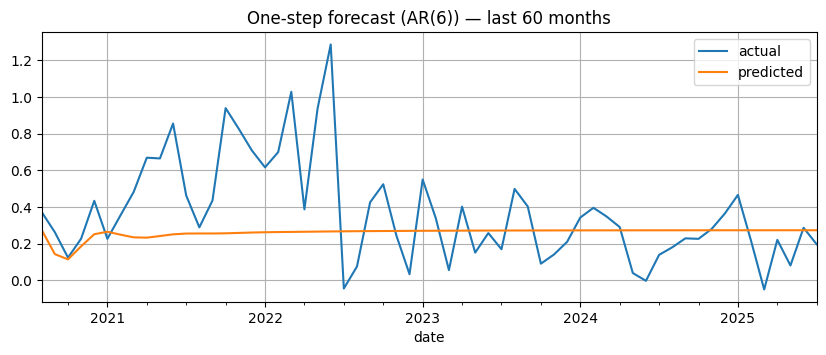

In [17]:
h_test = 60  # last 5 years
y_train, y_test = y.iloc[:-h_test], y.iloc[-h_test:]

fit_train = ARIMA(y_train, order=(best_p,0,0)).fit()

# one-step-ahead predictions for the test period
pred = fit_train.predict(start=y_test.index[0], end=y_test.index[-1])

mae  = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred)
print(f"Test MAE: {mae:.3f}  |  RMSE: {rmse:.3f}")

ax = y_test.plot(label="actual", title=f"One-step forecast (AR({best_p})) — last {h_test} months")
pred.plot(ax=ax, label="predicted")
plt.legend()
# plt.savefig("ar_best_onestep_test.png", dpi=200, bbox_inches="tight")
plt.show()


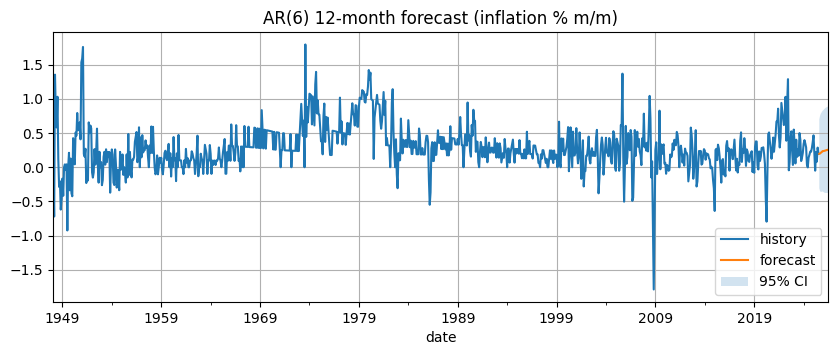

In [18]:
final_fit = ARIMA(y, order=(best_p,0,0)).fit()
fc = final_fit.get_forecast(steps=12)
fc_mean = fc.predicted_mean
fc_ci   = fc.conf_int(alpha=0.05)

ax = y.plot(label="history", title=f"AR({best_p}) 12-month forecast (inflation % m/m)")
fc_mean.plot(ax=ax, label="forecast")
plt.fill_between(fc_ci.index, fc_ci.iloc[:,0], fc_ci.iloc[:,1], alpha=0.2, label="95% CI")
plt.legend()
# plt.savefig("ar_best_12m_forecast.png", dpi=200, bbox_inches="tight")
plt.show()


In [19]:
z = df_tr["unrate_diff"].copy()
order_tbl = []
for p in range(0, 4):
    fit = ARIMA(z, order=(p,0,0)).fit()
    order_tbl.append((p, fit.aic, fit.bic))
print(pd.DataFrame(order_tbl, columns=["p","AIC","BIC"]).set_index("p"))

ar0 = ARIMA(z, order=(0,0,0)).fit()
ar1 = ARIMA(z, order=(1,0,0)).fit()

print("\nAR(0) vs AR(1) AIC:", ar0.aic, ar1.aic)


           AIC          BIC
p                          
0  1007.457322  1017.127691
1  1008.233095  1022.738649
2  1008.538286  1027.879024
3  1009.850685  1034.026608

AR(0) vs AR(1) AIC: 1007.4573216266386 1008.2330948981082


# L3: Moving Average (MA) & ARMA Models

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True


In [21]:
# 1) Load
cpi = (pd.read_csv("data/CPIAUCSL.csv", parse_dates=["observation_date"])
        .rename(columns={"observation_date":"date", "CPIAUCSL":"cpi"})
        .set_index("date").sort_index())

unrate = (pd.read_csv("data/UNRATE.csv", parse_dates=["observation_date"])
            .rename(columns={"observation_date":"date", "UNRATE":"unrate"})
            .set_index("date").sort_index())

# 2) Join & enforce monthly-start frequency (MS)
df = cpi.join(unrate, how="inner").asfreq("MS")

# 3) Transform
df["inflation_mom"] = np.log(df["cpi"]).diff() * 100         # % m/m
df["unrate_diff"]   = df["unrate"].diff()                     # pp change
df = df.dropna()
df[["inflation_mom","unrate_diff"]].head()


,inflation_mom,unrate_diff
date,,
1948-02-01,-0.042239,0.4
1948-03-01,-0.720800,0.2
1948-04-01,1.352514,-0.1
1948-05-01,0.794485,-0.4
1948-06-01,0.581397,0.1


In [22]:
y = df["inflation_mom"].copy()   # target we’ll model
z = df["unrate_diff"].copy()     # optional second series for comparison


Text(0.5, 1.0, 'PACF: Inflation (% m/m)')

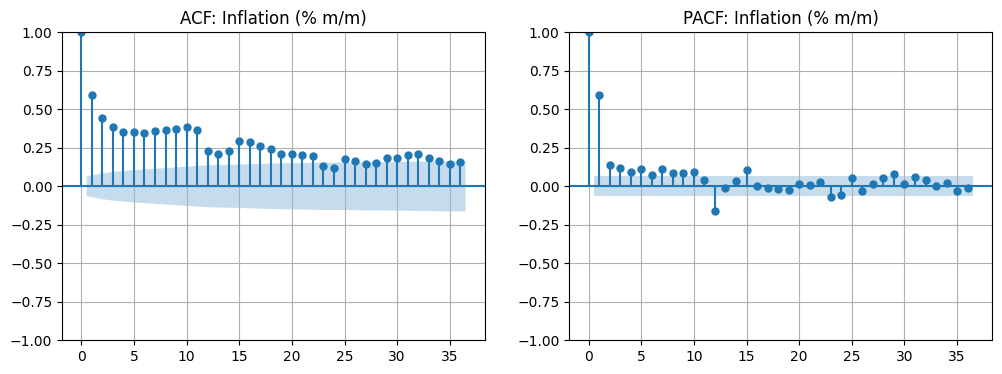

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
plot_acf(y, lags=36, ax=ax[0]); ax[0].set_title("ACF: Inflation (% m/m)")
plot_pacf(y, lags=36, ax=ax[1], method="ywm"); ax[1].set_title("PACF: Inflation (% m/m)")

# Optional: save figures
# fig.savefig("acf_pacf_inflation.png", dpi=200, bbox_inches="tight")


In [24]:
rows = []
for q in range(0, 5):         # try q = 0..4
    fit = ARIMA(y, order=(0,0,q)).fit()
    rows.append({"q": q, "AIC": fit.aic, "BIC": fit.bic})

ma_table = pd.DataFrame(rows).set_index("q").sort_values("AIC")
ma_table


,AIC,BIC
q,,
4,189.055492,218.066600
3,199.023512,223.199435
2,230.748783,250.089522
1,301.205104,315.710658
0,575.537670,585.208039


,lb_stat,lb_pvalue
12,160.925411,3.402314e-28
24,239.592382,1.889411e-37


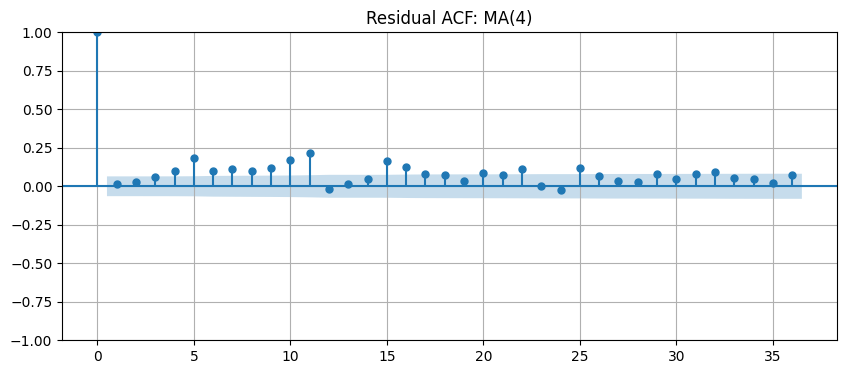

In [25]:
best_q = int(ma_table.index[0])
ma_best = ARIMA(y, order=(0,0,best_q)).fit()

fig, ax = plt.subplots()
plot_acf(ma_best.resid.dropna(), lags=36, ax=ax)
ax.set_title(f"Residual ACF: MA({best_q})")

# fig.savefig(f"ma{best_q}_resid_acf.png", dpi=200, bbox_inches="tight")

acorr_ljungbox(ma_best.resid.dropna(), lags=[12,24], return_df=True)


In [27]:
candidates = [(1,1), (2,1), (5,1), (2,2)]
rows, fits = [], {}
for p,q in candidates:
    fit = ARIMA(y, order=(p,0,q)).fit()
    fits[(p,q)] = fit
    rows.append({"p":p, "q":q, "AIC":fit.aic, "BIC":fit.bic})

arma_table = pd.DataFrame(rows).sort_values("AIC")
arma_table


/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/harshkyada/Desktop/ToU TS Challenge/venv/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,p,q,AIC,BIC
1,2,1,100.122691,124.298614
2,5,1,103.139936,141.821413
3,2,2,113.566867,142.577974
0,1,1,140.762437,160.103175


,lb_stat,lb_pvalue
12,36.059685,0.000317
24,71.461462,0.000001


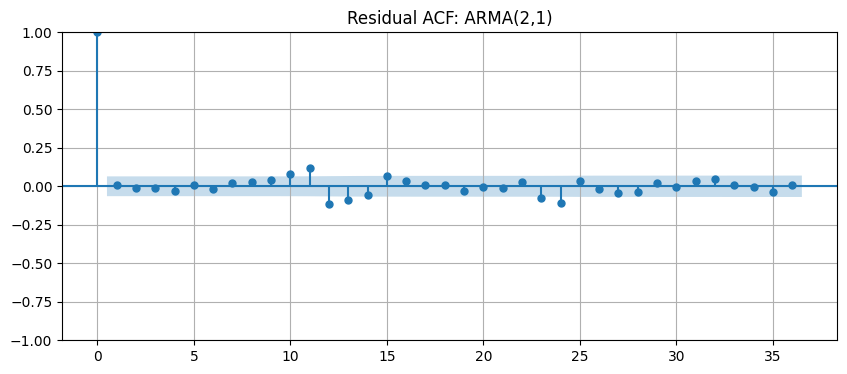

In [28]:
best_p, best_q = int(arma_table.iloc[0]["p"]), int(arma_table.iloc[0]["q"])
arma_best = fits[(best_p, best_q)]

fig, ax = plt.subplots()
plot_acf(arma_best.resid.dropna(), lags=36, ax=ax)
ax.set_title(f"Residual ACF: ARMA({best_p},{best_q})")

# fig.savefig(f"arma{best_p}{best_q}_resid_acf.png", dpi=200, bbox_inches="tight")

acorr_ljungbox(arma_best.resid.dropna(), lags=[12,24], return_df=True)


In [30]:
h_test = 60
y_train, y_test = y.iloc[:-h_test], y.iloc[-h_test:]

def one_step_score(order):
    m = ARIMA(y_train, order=order).fit()
    pred = m.predict(start=y_test.index[0], end=y_test.index[-1])
    return (mean_absolute_error(y_test, pred),
            mean_squared_error(y_test, pred),
            pred)

scores = {}
scores["AR(6)"] = one_step_score((6,0,0))
scores[f"MA({best_q})"] = one_step_score((0,0,best_q))
scores[f"ARMA({best_p},{best_q})"] = one_step_score((best_p,0,best_q))

pd.DataFrame(
    [(name, mae, rmse) for name,(mae,rmse,_) in scores.items()],
    columns=["Model","MAE","RMSE"]
).sort_values("RMSE")


,Model,MAE,RMSE
1,MA(1),0.206771,0.084215
0,AR(6),0.212630,0.088383
2,"ARMA(2,1)",0.232333,0.107923


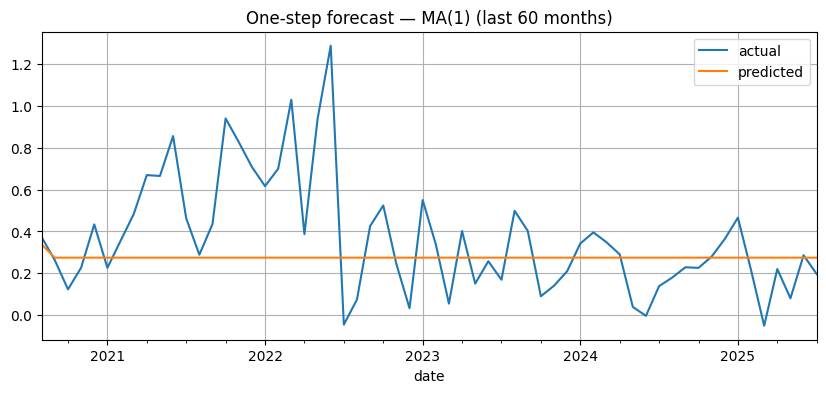

In [31]:
best_name = min(scores, key=lambda k: scores[k][1])   # lowest RMSE
pred_best = scores[best_name][2]

ax = y_test.plot(label="actual", title=f"One-step forecast — {best_name} (last {h_test} months)")
pred_best.plot(ax=ax, label="predicted")
plt.legend()
# plt.savefig("onestep_best.png", dpi=200, bbox_inches="tight")
plt.show()


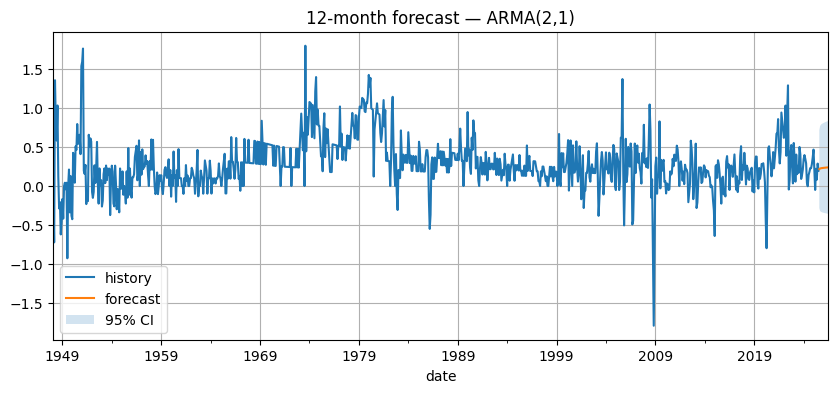

In [32]:
full_best = ARIMA(y, order=(best_p,0,best_q)).fit()
fc = full_best.get_forecast(steps=12)
fc_mean = fc.predicted_mean
fc_ci = fc.conf_int()          # 95% by default

ax = y.plot(label="history", title=f"12-month forecast — ARMA({best_p},{best_q})")
fc_mean.plot(ax=ax, label="forecast")
ax.fill_between(fc_ci.index, fc_ci.iloc[:,0], fc_ci.iloc[:,1], alpha=0.2, label="95% CI")
plt.legend()
# plt.savefig("forecast_12m.png", dpi=200, bbox_inches="tight")
plt.show()
